# 02 · Evaluation of the system

Reads the benchmark outputs (`reports/*.json`, produced by `jobintel bench all`). **Labels are assistant-proposed (not human-verified)** - see `reports/evaluation_report.md` for the caveats.

In [1]:
import os, sys, json, sqlite3
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 80); plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE = "#2a78d6"
R = lambda name: json.loads(Path('reports', name).read_text(encoding='utf-8'))

## 1. Retrieval: five systems, 10 queries, 95% bootstrap intervals

In [2]:
r = R("retrieval_benchmark.json")
rows = [{"system": k, **{m: v[m]["mean"] for m in ("ndcg@10", "p@5", "map@10", "recall@10", "mrr@10_strict")},
         "ci_low": v["ndcg@10"]["ci_low"], "ci_high": v["ndcg@10"]["ci_high"], "latency_ms": v["latency_ms"]["p50"]}
        for k, v in r["systems"].items()]
t = pd.DataFrame(rows).set_index("system"); t.round(3)

,ndcg@10,p@5,map@10,recall@10,mrr@10_strict,ci_low,ci_high,latency_ms
system,,,,,,,,
keyword,0.786,0.82,0.789,0.642,0.682,0.650,0.908,20.892
bm25,0.754,0.80,0.740,0.633,0.714,0.602,0.889,19.717
semantic,0.798,0.78,0.774,0.615,0.833,0.719,0.875,29.651
hybrid,0.842,0.82,0.830,0.681,0.783,0.747,0.931,31.791
hybrid_rerank,0.851,0.82,0.831,0.690,0.833,0.729,0.939,754.140


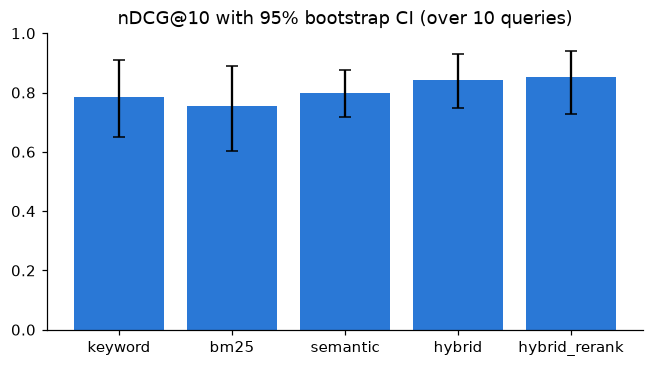

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(t.index, t["ndcg@10"], color=BLUE, yerr=[t["ndcg@10"] - t.ci_low, t.ci_high - t["ndcg@10"]], capsize=4)
ax.set_ylim(0, 1); ax.set_title("nDCG@10 with 95% bootstrap CI (over 10 queries)"); plt.show()

Per-query nDCG@10 - where do the systems disagree?

In [4]:
pd.DataFrame(r["per_query"]).T.round(2)

,keyword,bm25,semantic,hybrid,hybrid_rerank
q01,0.85,1.00,0.92,0.97,0.97
q02,1.00,1.00,0.95,1.00,0.95
q03,0.97,0.83,0.83,0.94,0.83
q04,0.51,0.43,0.63,0.63,0.99
q05,1.00,0.84,0.78,0.95,0.86
q06,0.50,0.50,0.70,0.70,0.87
q07,0.93,0.93,0.84,0.90,0.95
q08,0.43,0.32,0.76,0.58,0.36
q09,0.88,0.84,0.59,0.76,0.96
q10,0.79,0.86,0.98,0.98,0.76


## 2. Skill extraction: dev (before / after error analysis) and held-out test

In [5]:
s = R("skills_benchmark.json")
pd.DataFrame({"dev before fixes": s["dev_before_fixes"]["micro"], "dev after fixes": s["dev_after_fixes"]["micro"],
              "held-out test": s["micro"]}).T.round(3)

,precision,recall,f1
dev before fixes,0.980,0.798,0.880
dev after fixes,0.981,0.839,0.904
held-out test,0.914,0.705,0.796


In [6]:
pd.DataFrame(s["errors"]["false_negatives"], columns=["missed skill", "count"]).head(12)

,missed skill,count
0,Prompt engineering,3
1,OOV:LLM evaluation,2
2,AI agents,2
3,OOV:MCP,1
4,OOV:LangGraph,1
5,OOV:Adobe Analytics,1
6,OOV:Google Ads,1
7,OOV:Adobe Launch,1
8,OOV:Google Analytics,1
9,OOV:Google Tag Manager,1


## 3. Matching: ordering a candidate's eligible jobs (leave-one-candidate-out)

In [7]:
c = R("scoring_calibration.json")
pd.DataFrame(c["methods"]).T.round(3)

,mean_ndcg@10,ndcg_cv_en_ml_engineer,ndcg_cv_en_student_data_science,ndcg_cv_fr_data_engineer
retrieval order (RRF),0.665,0.416,0.676,0.903
rule-based evidence level,0.635,0.561,0.797,0.548
observed score (default weights),0.646,0.564,0.829,0.545
ranking score (default weights),0.661,0.572,0.804,0.606
"ranking score (weights fitted, leave-one-CV-out)",0.637,0.590,0.841,0.480


In [8]:
print(c["conclusion"]); c["eligibility_agreement"]

Fitted weights reach nDCG@10 0.789 in-sample but 0.637 out-of-sample vs 0.661 for the documented default weights; the fit does not generalise, so the default weights are kept.


{'excluded_and_labelled_ineligible': 21,
 'kept_but_labelled_ineligible': 8,
 'excluded_but_labelled_eligible': 0,
 'kept_and_labelled_eligible': 40,
 'label_says_unknown': 15,
 'precision_of_exclusions': 1.0,
 'recall_of_exclusions': 0.7241379310344828}

## 4. Assistant (RAG)

In [9]:
a = R("assistant_benchmark.json"); pd.DataFrame(a["modes"]).T

,questions,routing_accuracy,citation_validity,faithfulness,hallucination_rate,fallback_rate,answer_relevance,retrieval_relevance,forbidden_claims_in_final,latency_median_s,latency_max_s,est_llm_tokens_per_question,cost
deterministic,26,1.0,1.0,0.988,0.012,0.0,0.822,0.933,0,0.079,0.187,0,0 € (no model)
llm-ollama,26,1.0,0.985,0.721,0.279,0.192,0.846,0.92,0,8.303,24.544,691,0 € (local model)


## 5. Latency

In [10]:
l = R("latency.json"); pd.DataFrame(l["steps"]).T

,ms,chunks,median_ms,p95_ms,runs
load embedding model + open Chroma (cold),24174.0,NaN,NaN,NaN,NaN
build FAISS flat index from stored vectors (cold),835.0,3833.0,NaN,NaN,NaN
load cross-encoder (cold),4098.0,NaN,NaN,NaN,NaN
search · keyword (warm),NaN,NaN,24.0,26.8,20.0
search · bm25 (warm),NaN,NaN,19.3,32.9,20.0
search · semantic (warm),NaN,NaN,34.1,95.4,20.0
search · hybrid (warm),NaN,NaN,70.7,89.2,20.0
search · hybrid_rerank (warm),NaN,NaN,735.8,878.5,20.0
embed one query,NaN,NaN,21.0,26.9,20.0
read + parse CV,NaN,NaN,12.5,14.9,10.0
